# Explaining alerts

A bank cannot act on an unexplained score: a compliance officer must understand **why** an
account was flagged, and a regulator may ask for the evidence. AML-GraphMiner offers six
complementary explanation methods behind one data model (`Explanation`):

| method | works with | nature |
|---|---|---|
| `patterns` | motif scanner | exact — the alert, its accounts, transactions and numbers |
| `occlusion` | any detector | model-agnostic — remove neighbours and watch the score move |
| `gnnexplainer` | GNN detectors | GNNExplainer (Ying et al., 2019): a mask learned per alert |
| `pgexplainer` | GNN detectors | PGExplainer (Luo et al., 2020): one explainer network trained on many alerts |
| `captum` | GNN detectors | Captum Integrated Gradients: neighbours, account features and transaction features |
| `attention` | GAT detectors | attention weights (descriptive, not causal) |

This notebook runs the first two on synthetic data; the GNN ones are shown in the last
section and execute when PyTorch Geometric (and Captum) are installed. The same methods are
available from `amlgm explain --method ...`, the REST API and the web interface.

In [1]:
%pip install -q "aml-graphminer[viz]"

In [2]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import aml_graphminer as aml
from aml_graphminer.detectors.bundle import MotifDetector, TabularDetector
from aml_graphminer.explainers import (
    OcclusionExplainer,
    TransactionIndex,
    detector_score_fn,
    explain_with_patterns,
    plot_explanation,
)
from aml_graphminer.utils import has_module

warnings.filterwarnings("ignore")

df = aml.generate_transactions(
    n_accounts=900, n_background=7000, days=10, illicit_ratio=0.02, seed=21
)
index = TransactionIndex(df)
masks = aml.temporal_split(df)
print(f"{len(df):,} transactions; test split starts at tx {int(df.index[masks['test']][0])}")

7,159 transactions; test split starts at tx 5727


## 1. Exact evidence from the motif scanner

Train a calibrated motif detector (the calibration learns each motif's precision on the
validation split so that alerts of different detectors can be ranked together), then explain
the highest-scoring test transaction.

In [3]:
motifs = MotifDetector.fit(df, fractions=(0.6, 0.2, 0.2))
result = motifs.scanner.scan(df)
test_scores = motifs.score(df[masks["test"]], context=df[~masks["test"]])
top_tx = int(test_scores.sort_values(ascending=False).index[0])
print("explaining transaction", top_tx, "| score", round(float(test_scores[top_tx]), 3))
by_pattern = explain_with_patterns(df, top_tx, result, motifs.threshold)
print(by_pattern.to_markdown())

explaining transaction 6718 | score 0.383
### Transaction 6718 — patterns
- score: **0.383** (threshold 0.735)
- Part of 1 structural alert(s). gather_scatter: money is collected by a hub then redistributed to other accounts (hub=11_0000305F, n_sources=5, n_targets=3, gathered_amount=5,586.14, scattered_amount=5,134.77, conservation_ratio=0.919).
- pattern `gather_scatter` (alert score 0.38)

| tx | sender → receiver | amount | importance |
|---|---|---:|---:|
| 5630 | 4_00002C2E → 11_0000305F | 206.90 | +0.383 |
| 5775 | 6_00001661 → 11_0000305F | 127.37 | +0.383 |
| 5950 | 11_0000305F → 2_0000263F | 288.84 | +0.383 |
| 6004 | 1_00001909 → 11_0000305F | 932.53 | +0.383 |
| 6316 | 7_00002CAB → 11_0000305F | 1,441.04 | +0.383 |


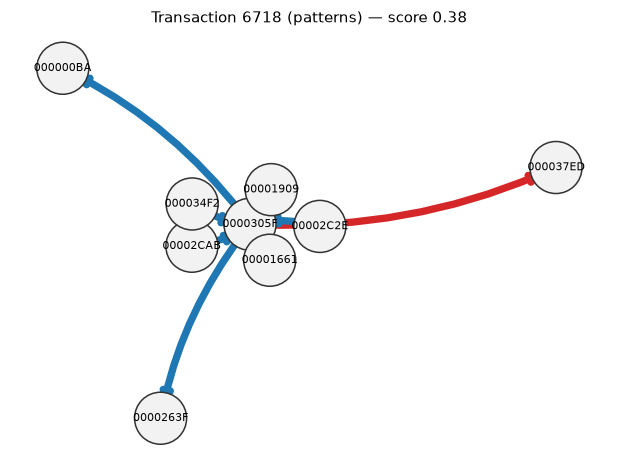

In [4]:
plot_explanation(by_pattern)
plt.show()

Reading the figure: the explained transaction is red; every other edge belongs to the same
alert and is drawn thicker the higher the alert's score. In the JSON form each pattern entry
lists the evidence dictionary of the detector (hub account, number of counterparties, time
span, conservation ratio, ...) — everything needed to write the suspicious-activity narrative.

In [5]:
by_pattern.patterns[0]

{'pattern': 'gather_scatter', 'score': 0.38340941721720445, 'accounts': ['11_0000305F', '4_00002C2E', '4_000034F2', '1_00001909', '6_00001661', '7_00002CAB', '10_000000BA', '2_0000263F', '3_000037ED'], 'tx_ids': [5630, 5775, 6004, 6316, 6428, 5950, 6327, 6718], 'start': '2022-09-08T08:05:00', 'end': '2022-09-09T12:22:00', 'total_amount': 5586.14, 'evidence': {'hub': '11_0000305F', 'n_sources': 5, 'n_targets': 3, 'gathered_amount': 5586.137759, 'scattered_amount': 5134.774624, 'conservation_ratio': 0.919199}, 'description': 'gather_scatter: money is collected by a hub then redistributed to other accounts (hub=11_0000305F, n_sources=5, n_targets=3, gathered_amount=5,586.14, scattered_amount=5,134.77, conservation_ratio=0.919).'}

## 2. Model-agnostic occlusion for a learned detector

`OcclusionExplainer` removes each transaction (and each account) of the neighbourhood and
measures the score drop. It is **local**: the neighbourhood radius `hops` must cover what the
model looks at (a 2-layer GNN sees 2 hops).

In [6]:
tabular = TabularDetector.fit(df, "rf", seed=0)
scores = tabular.score(df[masks["test"]], context=df[~masks["test"]])
target = int(scores.sort_values(ascending=False).index[0])
for hops in (1, 2):
    explanation = OcclusionExplainer(
        detector_score_fn(tabular), hops=hops, max_edges=40, threshold=tabular.threshold
    ).explain(df, target, index)
    print(f"--- hops={hops}: {len(explanation.edges)} transactions considered")
    print(explanation.summary)

--- hops=1: 14 transactions considered
Score 0.337 computed with 13 neighbouring transactions. The most influential neighbour is transaction 6475 (1_00001A1B → 6_00002B6B, 89.97): it raises the score by 0.129.
--- hops=2: 40 transactions considered
Score 0.153 computed with 39 neighbouring transactions. The most influential neighbour is transaction 6632 (6_00002B6B → 5_000016B4, 18,163.28): it lowers the score by 0.025.


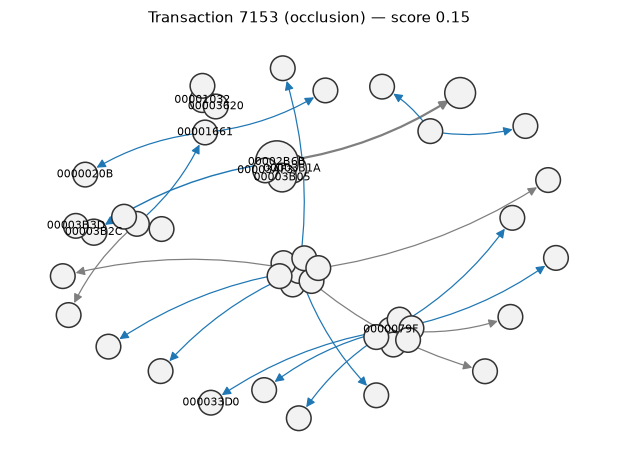

In [7]:
plot_explanation(explanation)
plt.show()

**Attribute view.** Besides neighbours, the explanation says which *raw attributes* of the
explained transaction (amount, currency, payment format, banks) push its score up or down:
each one is replaced by the typical value of the neighbourhood and the score is recomputed.
Because the other columns are left unchanged, derived features (e.g. paid / received ratio)
change too — read it as a sensitivity, not as a causal effect.

In [8]:
pd.DataFrame(explanation.features).round(4)

,name,value,importance
0,amount,156892.88,0.1380
1,amount_received,156892.88,-0.0791
2,transaction_type,ACH,0.0000
3,currency,US Dollar,0.0000
4,currency_received,US Dollar,0.0000
5,sender_bank,1,0.0000
6,receiver_bank,6,0.0000


## 3. Sanity checks you should always run

* **Fidelity** — does removing the most important neighbours really lower the score?
* **Stability** — do two seeds give the same top neighbours?

The first is cheap to check with the same tooling:

In [9]:
top_ids = [e.tx_id for e in explanation.edges if e.role != "target"][:3]
subset = df.drop(index=top_ids)
before = float(tabular.score(df.loc[[target]], context=df.drop(index=target)).iloc[0])
after = float(tabular.score(subset.loc[[target]], context=subset.drop(index=target)).iloc[0])
print(
    f"score with the full history: {before:.3f}  |  without its 3 most important neighbours: {after:.3f}"
)

score with the full history: 0.386  |  without its 3 most important neighbours: 0.346


## 4. GNN explainers (needs `aml-graphminer[gnn]`)

The code below trains a small GAT and explains its strongest test alert with GNNExplainer,
PGExplainer and the attention weights. It is skipped automatically when PyTorch Geometric is
missing.

In [10]:
GNN = has_module("torch") and has_module("torch_geometric")
if GNN:
    from aml_graphminer.detectors.gnn import GNNConfig, GNNDetector
    from aml_graphminer.explainers import (
        AttentionExplainer,
        GNNExplainerAdapter,
        PGExplainerAdapter,
    )

    cfg = GNNConfig(
        kind="gat", hidden=32, layers=2, epochs=5, batch_size=1024, num_neighbors=[8, 4]
    )
    gnn = GNNDetector.fit(df, cfg, seed=0)
    gnn_scores = gnn.score(df[masks["test"]], context=df[~masks["test"]])
    ranked = gnn_scores.sort_values(ascending=False)
    gnn_target = int(ranked.index[0])
    for explainer in (
        GNNExplainerAdapter(gnn.trained, hops=2),
        AttentionExplainer(gnn.trained, hops=2),
    ):
        print(explainer.explain(df, gnn_target, index).to_markdown())
else:
    print("PyTorch Geometric is not installed here: GNN explainers skipped.")

### Transaction 7117 — gnnexplainer
- score: **0.942** (threshold 0.395)
- gnnexplainer: score 0.942; most influential neighbouring transaction 7158 (6_00003B3D → 10_00003AF3, importance 0.797). Without its 4 neighbouring transactions the score would be 0.940 (measured neighbourhood effect +0.003).

| tx | sender → receiver | amount | importance |
|---|---|---:|---:|
| 7158 | 6_00003B3D → 10_00003AF3 | 147,305.76 | +0.797 |
| 7153 | 1_00003B1A → 6_00002B6B | 156,892.88 | +0.214 |
| 7152 | 2_00003B05 → 1_00003B1A | 160,540.75 | +0.194 |
| 7155 | 3_00003B2C → 6_00003B3D | 150,805.08 | +0.186 |
### Transaction 7117 — attention
- score: **0.942** (threshold 0.395)
- attention: score 0.942; most influential neighbouring transaction 7153 (1_00003B1A → 6_00002B6B, importance 0.478). Without its 4 neighbouring transactions the score would be 0.940 (measured neighbourhood effect +0.003).

| tx | sender → receiver | amount | importance |
|---|---|---:|---:|
| 7153 | 1_00003B1A → 6_00002B6B | 156

**PGExplainer** is *parametric*: instead of optimising one mask per alert, it trains once — on
the neighbourhoods of the 15 strongest alerts here — a small network that predicts the
importance of every transaction from the embeddings of its two accounts. New alerts are then
explained in one forward pass, consistently with each other. When every transaction receives
the same mask, the explainer is telling you that the model barely uses the neighbourhood for
this alert — the decision comes from the transaction and account features, which Captum below
attributes precisely.

### Transaction 7117 — pgexplainer
- score: **0.942** (threshold 0.395)
- pgexplainer: score 0.942; no neighbouring transaction stands out (all masks ≈ 0.00): the prediction is driven by the transaction and account features rather than by the neighbourhood — see the captum method. (explainer trained on 15 alert neighbourhoods). Without its 4 neighbouring transactions the score would be 0.940 (measured neighbourhood effect +0.003).

| tx | sender → receiver | amount | importance |
|---|---|---:|---:|
| 7153 | 1_00003B1A → 6_00002B6B | 156,892.88 | +0.000 |
| 7152 | 2_00003B05 → 1_00003B1A | 160,540.75 | +0.000 |
| 7158 | 6_00003B3D → 10_00003AF3 | 147,305.76 | +0.000 |
| 7155 | 3_00003B2C → 6_00003B3D | 150,805.08 | +0.000 |


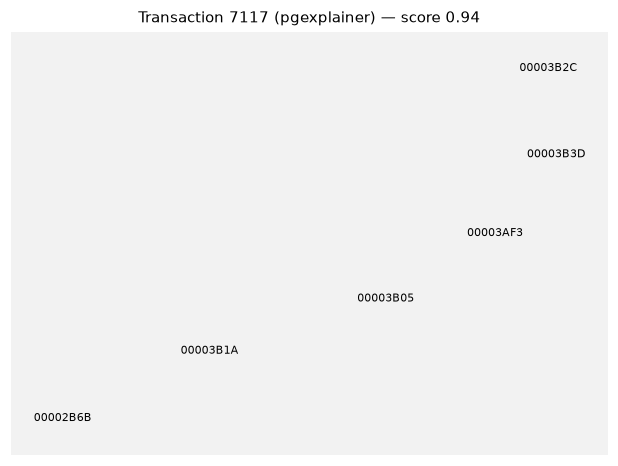

In [11]:
if GNN:
    pg = PGExplainerAdapter(gnn.trained, hops=2, epochs=20)
    pg.fit(df, [int(t) for t in ranked.index[:15]], index)
    pg_explanation = pg.explain(df, gnn_target, index)
    print(pg_explanation.to_markdown())
    plot_explanation(pg_explanation)
    plt.show()

**Captum** (Integrated Gradients) attributes the probability of laundering to the neighbouring
transactions, to the features of the two accounts (`sender.*`, `receiver.*`) and to the
features of the transaction itself (`tx.*`: amount, payment format, recent activity windows
...), with a baseline equal to an average transaction. Needs `aml-graphminer[explain]`.

In [12]:
if GNN and has_module("captum"):
    from aml_graphminer.explainers import CaptumExplainerAdapter

    captum_explanation = CaptumExplainerAdapter(gnn.trained, hops=2).explain(df, gnn_target, index)
    print(captum_explanation.summary)
    captum_table = pd.DataFrame(captum_explanation.features).round(4)
else:
    captum_table = "Captum or PyTorch Geometric is not installed here: Captum attributions skipped."
captum_table

captum: score 0.942; most influential neighbouring transaction 7158 (6_00003B3D → 10_00003AF3, importance 0.004). Most influential feature: tx.r_mean_all (standardised value 4.80) raises the probability by 0.056. Without its 4 neighbouring transactions the score would be 0.940 (measured neighbourhood effect +0.003).


,name,value,importance
0,tx.r_mean_all,4.8048,0.0562
1,tx.s_mean_7d,5.8305,0.0452
2,tx.r_mean_24h,4.0054,0.0424
3,tx.log_paid,3.5780,0.0330
4,tx.s_mean_1h,3.8467,0.0307
5,tx.r_mean_1h,3.2183,0.0253
6,tx.log_recv,3.1173,0.0242
7,tx.s_mean_all,5.8305,0.0188
8,tx.r_mean_7d,4.8048,0.0156
9,tx.s_sum_24h,1.9531,0.0147
